# 04. Constrained model predictive control

Original study laboratory. All generated data are synthetic.

At each sample solve

$$
\min_U\sum_{j=1}^{N_p}\lVert\hat x_{k+j}-r\rVert_Q^2+
\sum_{j=0}^{N_c-1}\lVert\Delta u_{k+j}\rVert_R^2.
$$

subject to $\hat x^+=A\hat x+B u$, actuator bounds and move bounds.
Only the first optimized action is applied. Beyond the control horizon, hold
the final move. Inspect solver failures as well as tracking error.
The second experiment uses two coupled states and two constrained inputs.

## Prepare the environment

Run the next cell once in Colab. Locally, install `requirements.txt` and open this notebook within the repository. The cell only downloads the public repository when running in Colab and no checkout is present.

In [1]:
from pathlib import Path
import sys, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not Path("python/intelligent_control").exists():
    checkout = Path("/content/intelligent-process-control")
    if not checkout.exists():
        subprocess.run(["git", "clone", "https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(checkout / "requirements.txt")], check=True)
    import os
    os.chdir(checkout)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "python/intelligent_control").is_dir())
sys.path.insert(0, str(ROOT / "python"))
print("Environment ready")

Environment ready


## Read the method visually

![Unit 04 conceptual diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/course/figures/learning/unit-04.png)

Solid points are past observations and dashed points are predictions. The shaded interval marks the only action applied before remeasurement. The curve is a conceptual sketch, not the optimizer output. In the computed result, inspect input and move limits, horizon choices and solver success alongside SISO tracking and the two MIMO outputs.

The conceptual diagram is deliberately separate from the computed experiment below. [Editable SVG](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/figures/learning/unit-04.svg).

## Run the experiment

Read the model and controller definitions alongside the results. Every rerun writes the metrics, trace CSV files and figure from the current parameters. Unit 7 includes nested optimization and costs more than the other units.

In [2]:
from intelligent_control.experiments import run_unit
import json
result = run_unit(4, ROOT / "laboratories/04-model-predictive-control/results")
print(json.dumps(result["summary"], indent=2))

{
  "siso": {
    "iae": 1.8629781535608758,
    "ise": 0.3616383867970022,
    "itae": 51.41033115057472,
    "control_energy": 25.09802190370109,
    "total_variation": 2.0807484762358124,
    "constraint_violation": 0.0,
    "final_error": 6.722017445448536e-07
  },
  "solver_failures": 0,
  "mimo_solver_failures": 0,
  "max_move": 0.0500000000000011,
  "mimo_final_output": [
    0.649994719028756,
    0.5500035158810259
  ],
  "mimo_max_output": 0.6524843061745139,
  "note": "Full state is measured; the additive inlet disturbance is measured for prediction. No state estimator is assumed.",
  "elapsed_seconds": 21.800774000003003
}


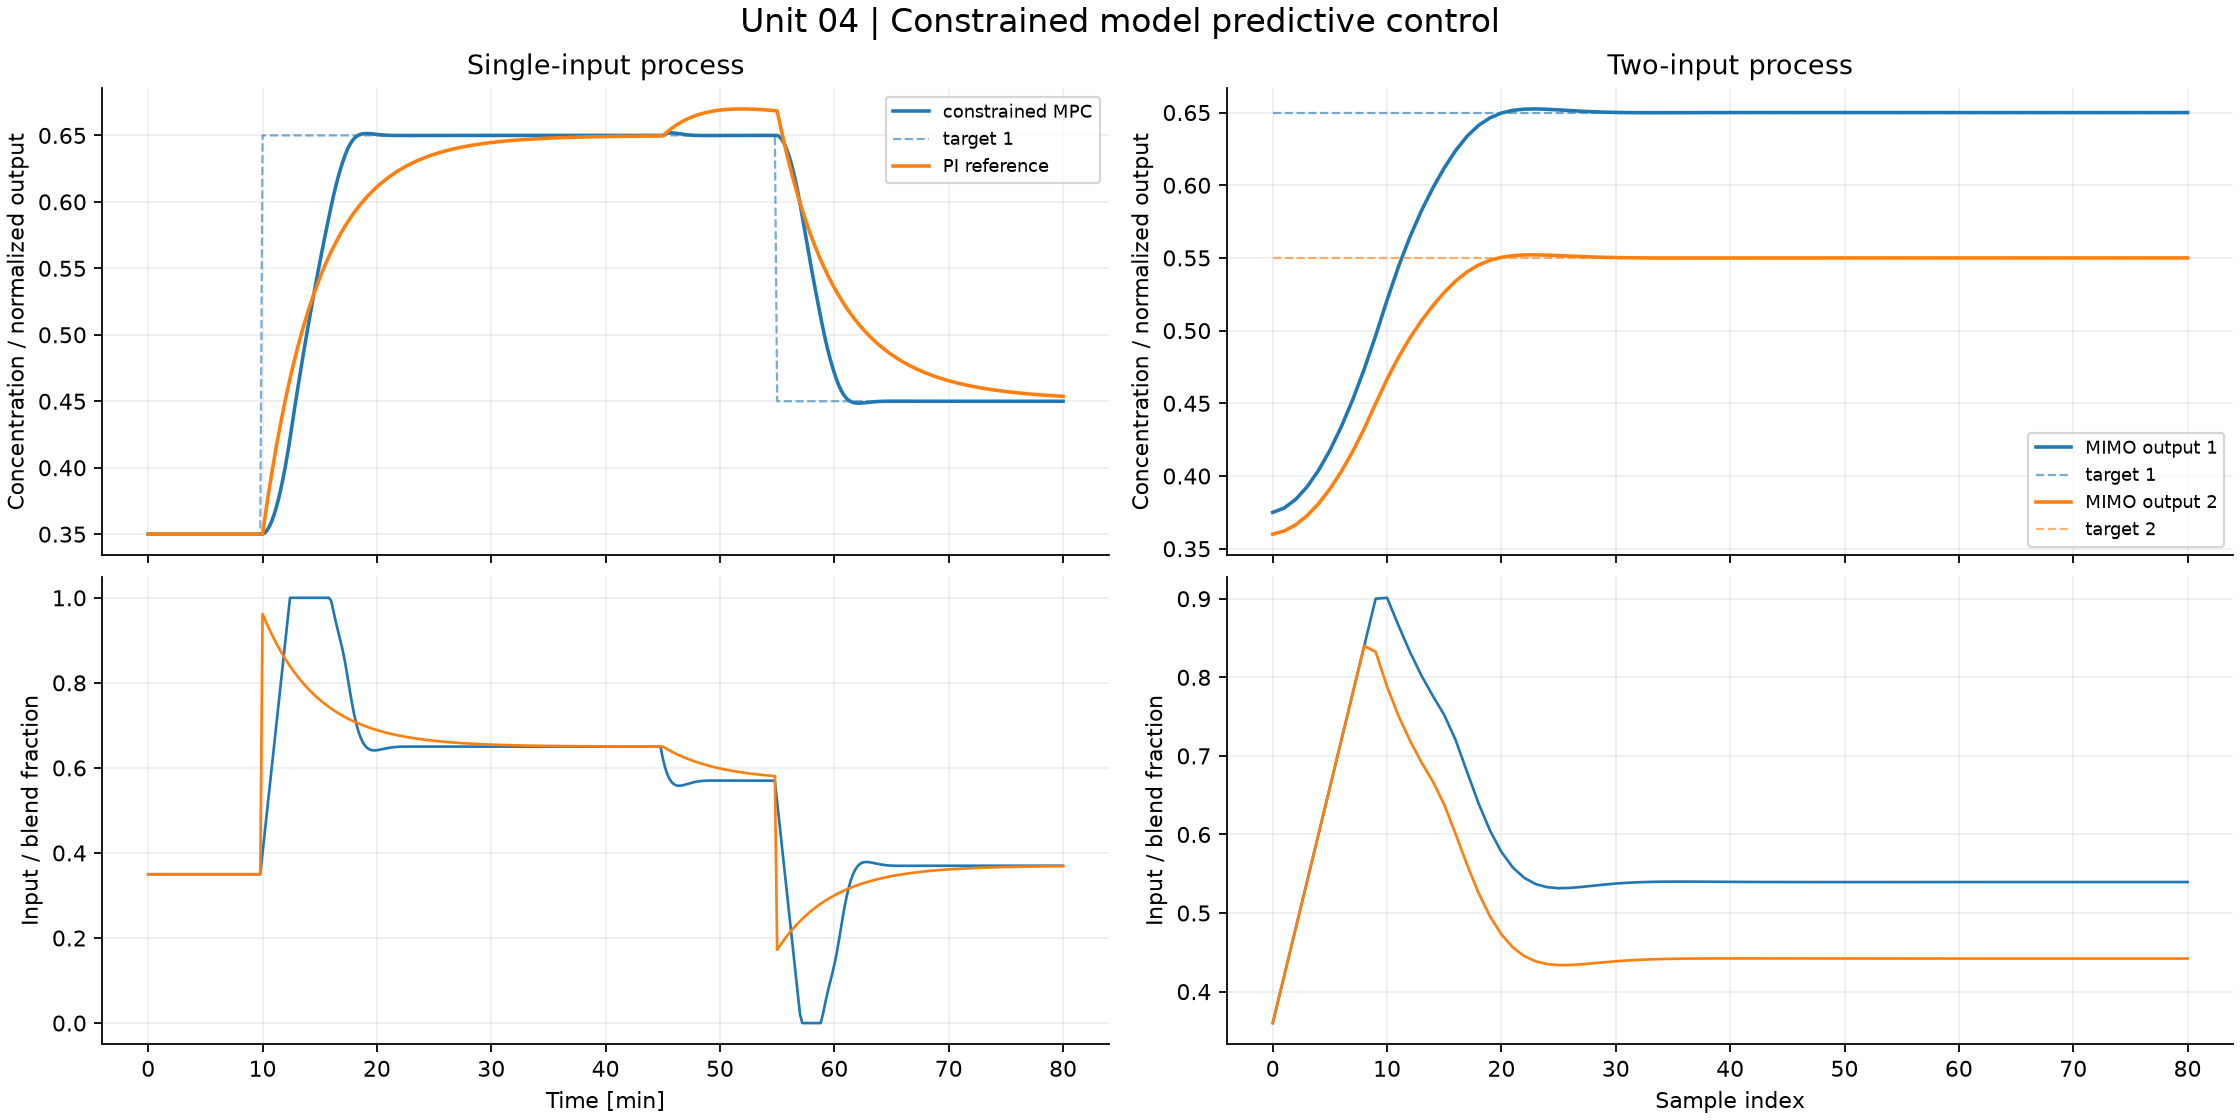

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "laboratories/04-model-predictive-control/results/comparison.png")))

## Inspect the evidence

1. Identify the physical assumptions, input limits and units.
2. Explain a visible transient using the governing equation.
3. Change one model or controller parameter, rerun and compare the saved metrics.
4. State what the test does and does not establish.

Use the [course guide](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/README.md), [worked problems](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/problem-sets/README.md) and [benchmark inventory](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/README.md) for the corresponding derivations and extensions.

## Apply this unit to the article benchmarks

[Original article names and detailed TikZ atlas](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/DIAGRAMS.md) · [Download the vector atlas](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/figures/tikz/benchmark-atlas.pdf)

![Tennessee Eastman process control problem — article section 3.13](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/benchmarks/figures/tikz/13-tennessee-eastman.png)

The atlas identifies every benchmark by its original paper name and repository alias, with equipment, states and signals. The Tennessee Eastman companion plate maps the 12 commands and 41 measurements.

[Worked benchmark study for Unit 04](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/learning/unit-04.md)

![Unit 04 benchmark study](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/benchmarks/learning/figures/unit-04.png)

Read the per-model method, chosen signals, numerical results and interpretation in the linked study. The learning track declares its local-model approximations and separates equation-based experiments from external datasets and simulators. It does not turn an unavailable measured record into a synthetic benchmark result.